In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

In [6]:
zip_file = zipfile.ZipFile(r"C:\Users\ELCOT\Downloads\hotel_bookings.csv.zip")

df = pd.read_csv(zip_file.open('hotel_bookings.csv'))

print(df)

               hotel  is_canceled  lead_time  arrival_date_year  \
0       Resort Hotel            0        342               2015   
1       Resort Hotel            0        737               2015   
2       Resort Hotel            0          7               2015   
3       Resort Hotel            0         13               2015   
4       Resort Hotel            0         14               2015   
...              ...          ...        ...                ...   
119385    City Hotel            0         23               2017   
119386    City Hotel            0        102               2017   
119387    City Hotel            0         34               2017   
119388    City Hotel            0        109               2017   
119389    City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
0                    July                        27   
1                    July                        27   
2                    July     

In [7]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [8]:
print("Dataset Shape:", df.shape)

Dataset Shape: (119390, 32)


In [9]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')


In [10]:
print("Data Types:")
print(df.dtypes)

Data Types:
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                 

In [11]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340


In [12]:


df['children'] = df['children'].fillna(df['children'].median())

df['agent'] = df['agent'].fillna(0)

df['company'] = df['company'].fillna(0)

df['country'] = df['country'].fillna(df['country'].mode()[0])

print("Missing Values After Handling:")
print(df.isnull().sum())

Missing Values After Handling:
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                    

In [13]:


from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    df[col] = le.fit_transform(df[col])

print("Categorical Columns Encoded")
print(df.head())

C:\Users\ELCOT\AppData\Local\Temp\ipykernel_10684\3018150795.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include='object').columns


Categorical Columns Encoded
   hotel  is_canceled  lead_time  arrival_date_year  arrival_date_month  \
0      1            0        342               2015                   5   
1      1            0        737               2015                   5   
2      1            0          7               2015                   5   
3      1            0         13               2015                   5   
4      1            0         14               2015                   5   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...             0   
1             

In [14]:


num_cols = ['lead_time', 'adults', 'children',
            'stays_in_week_nights', 'adr']

print(df[num_cols].head())

   lead_time  adults  children  stays_in_week_nights   adr
0        342       2       0.0                     0   0.0
1        737       2       0.0                     0   0.0
2          7       1       0.0                     1  75.0
3         13       1       0.0                     1  75.0
4         14       2       0.0                     2  98.0


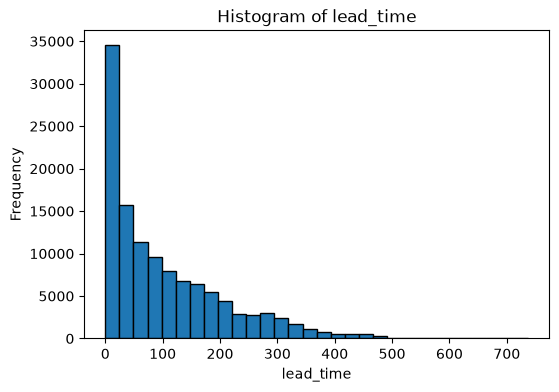

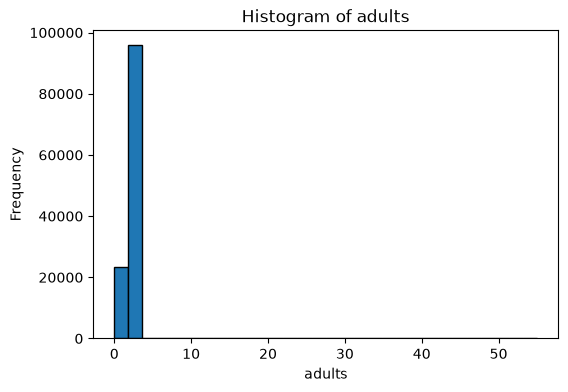

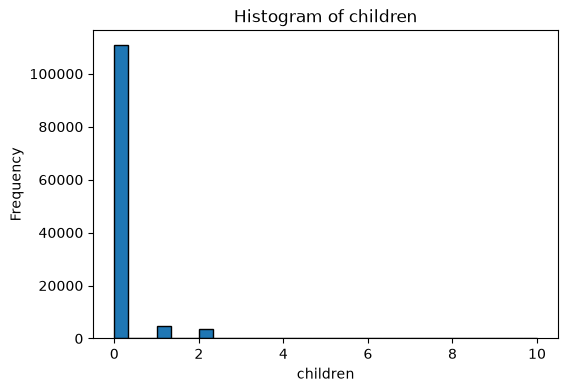

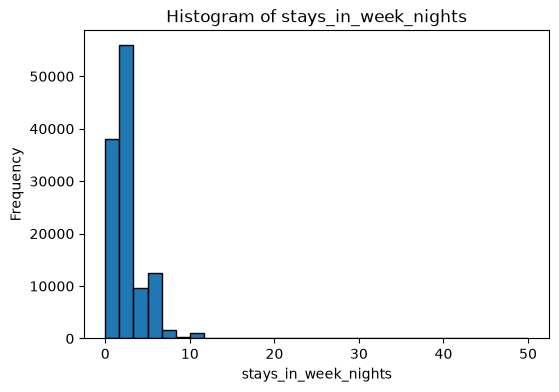

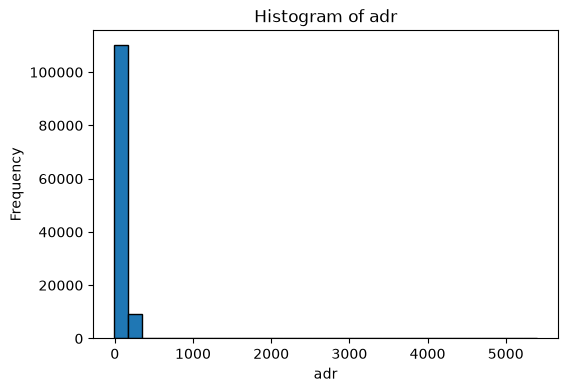

In [15]:


for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=30, edgecolor='black')
    plt.title("Histogram of " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

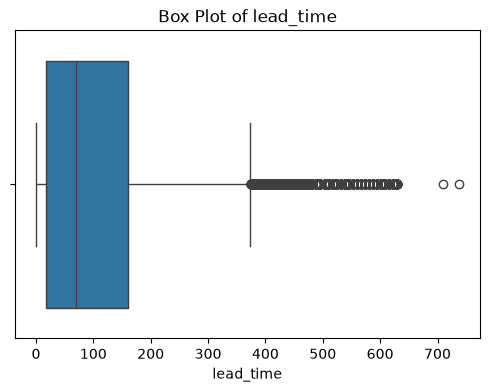

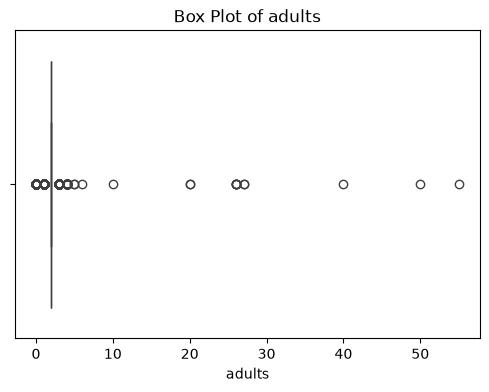

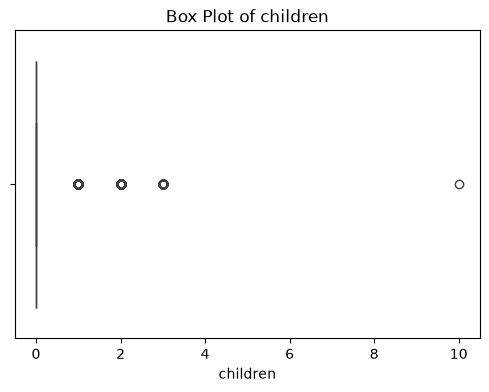

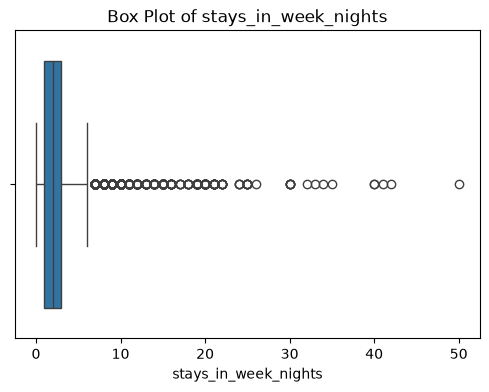

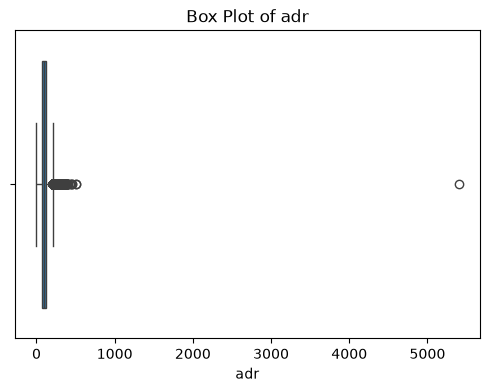

In [16]:


for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title("Box Plot of " + col)
    plt.xlabel(col)
    plt.show()

In [17]:


for col in num_cols:
    print("\nColumn:", col)
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


Column: lead_time
Skewness: 1.3465498727254264
Kurtosis: 1.696448848558545

Column: adults
Skewness: 18.317804759206098
Kurtosis: 1352.1151163093687

Column: children
Skewness: 4.112669999376718
Kurtosis: 18.674463656826877

Column: stays_in_week_nights
Skewness: 2.8622492420671244
Kurtosis: 24.284554815417337

Column: adr
Skewness: 10.53021398218952
Kurtosis: 1013.1898508588172


In [18]:


for col in num_cols:

    skew = df[col].skew()

    print("\nColumn:", col)

    if skew > 0.5:
        print("Distribution: Positively Skewed")

    elif skew < -0.5:
        print("Distribution: Negatively Skewed")

    else:
        print("Distribution: Approximately Normal")


Column: lead_time
Distribution: Positively Skewed

Column: adults
Distribution: Positively Skewed

Column: children
Distribution: Positively Skewed

Column: stays_in_week_nights
Distribution: Positively Skewed

Column: adr
Distribution: Positively Skewed


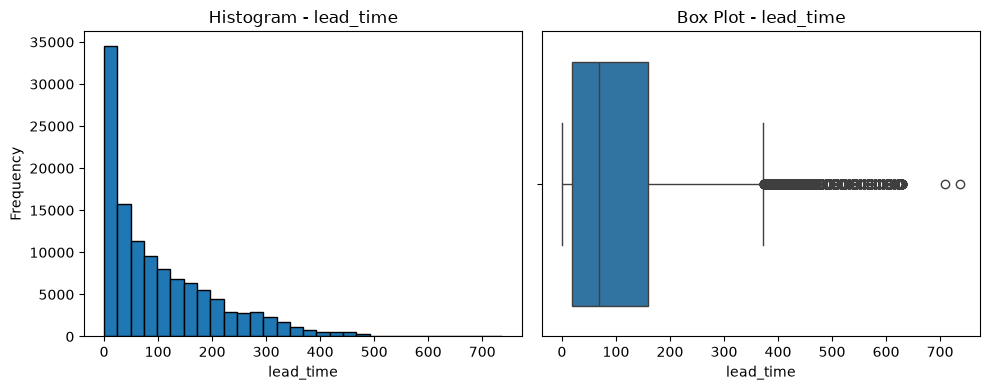

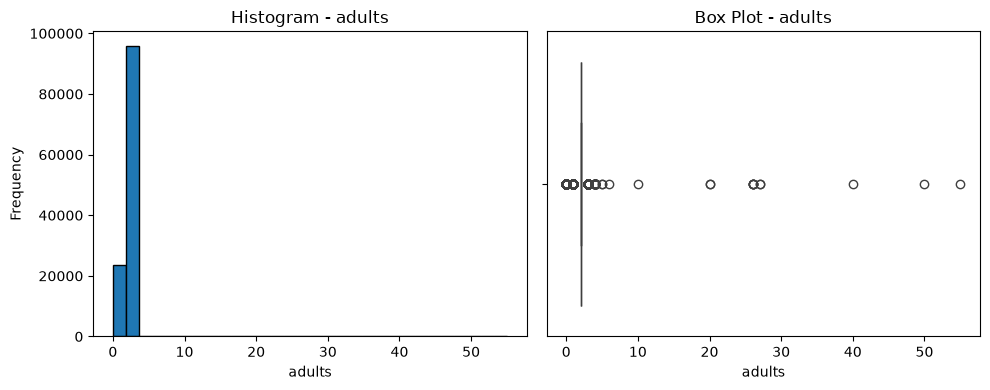

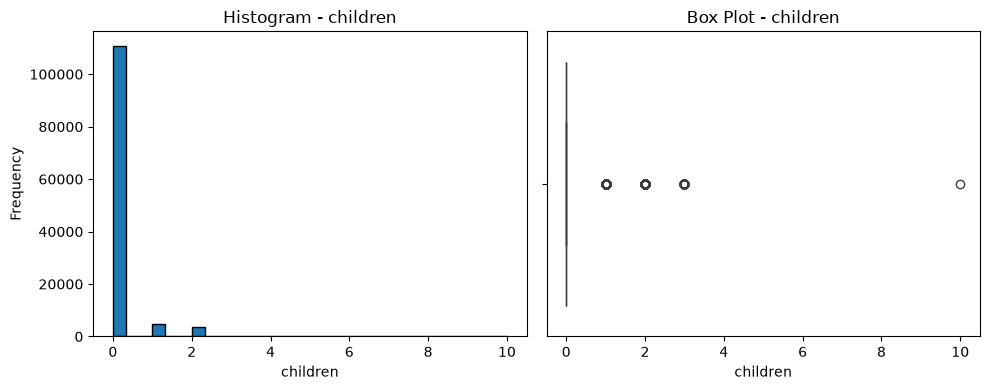

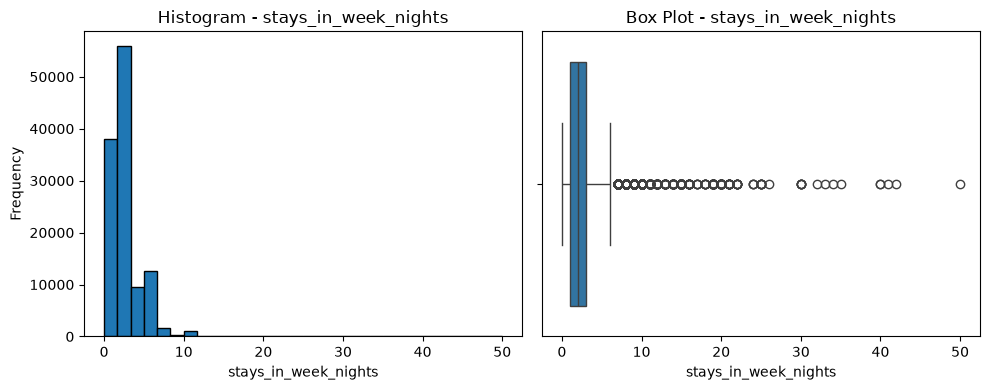

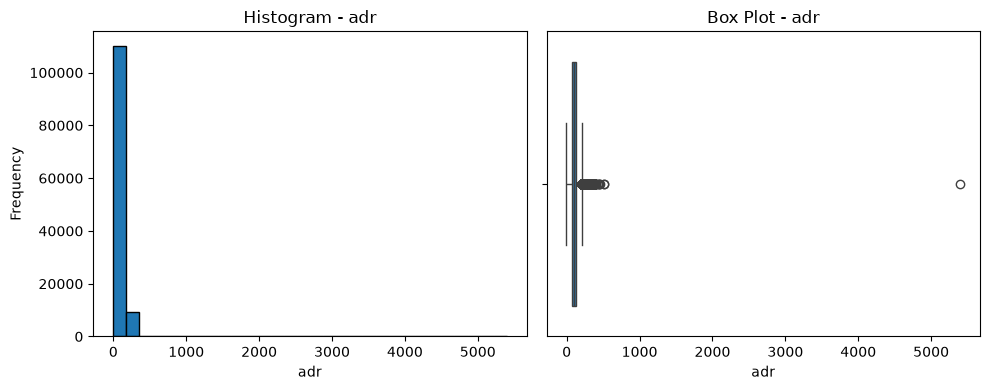

In [19]:


for col in num_cols:

    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.hist(df[col], bins=30, edgecolor='black')
    plt.title("Histogram - " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.subplot(1,2,2)
    sns.boxplot(x=df[col])
    plt.title("Box Plot - " + col)

    plt.tight_layout()
    plt.show()

In [20]:


print("Statistical Summary:")
print(df[num_cols].describe())

print("\nSkewness:")
print(df[num_cols].skew())

print("\nKurtosis:")
print(df[num_cols].kurt())

Statistical Summary:
           lead_time         adults       children  stays_in_week_nights  \
count  119390.000000  119390.000000  119390.000000         119390.000000   
mean      104.011416       1.856403       0.103886              2.500302   
std       106.863097       0.579261       0.398555              1.908286   
min         0.000000       0.000000       0.000000              0.000000   
25%        18.000000       2.000000       0.000000              1.000000   
50%        69.000000       2.000000       0.000000              2.000000   
75%       160.000000       2.000000       0.000000              3.000000   
max       737.000000      55.000000      10.000000             50.000000   

                 adr  
count  119390.000000  
mean      101.831122  
std        50.535790  
min        -6.380000  
25%        69.290000  
50%        94.575000  
75%       126.000000  
max      5400.000000  

Skewness:
lead_time                1.346550
adults                  18.317805
children